<a href="https://colab.research.google.com/github/ahmadmukhtasor-0309-lgtm/Tugas-Machine-Learning/blob/main/Feature_Selection_%26_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
titanic = pd.read_csv("train.csv")

print("Jumlah baris dan kolom:", titanic.shape)

titanic.head()

Jumlah baris dan kolom: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
print("Jumlah data kosong setiap kolom:")
print(titanic.isnull().sum())

Jumlah data kosong setiap kolom:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [ ]:
X = titanic[["Age", "Fare", "Sex", "Embarked"]]
y = titanic["Survived"]

print("Fitur:")
print(X.head())

print("\nTarget:")
print(y.head())

Fitur:
    Age     Fare     Sex Embarked
0  22.0   7.2500    male        S
1  38.0  71.2833  female        C
2  26.0   7.9250  female        S
3  35.0  53.1000  female        S
4  35.0   8.0500    male        S

Target:
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data training :", X_train.shape)
print("Data testing  :", X_test.shape)

Data training : (712, 4)
Data testing  : (179, 4)


In [ ]:
fitur_numerik = ["Age", "Fare"]
fitur_kategorikal = ["Sex", "Embarked"]

print("Fitur numerik:", fitur_numerik)
print("Fitur kategorikal:", fitur_kategorikal)

Fitur numerik: ['Age', 'Fare']
Fitur kategorikal: ['Sex', 'Embarked']


In [ ]:
numerik_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [ ]:
kategori_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [ ]:
preprocessor = ColumnTransformer([
    ("numerik", numerik_pipeline, fitur_numerik),
    ("kategori", kategori_pipeline, fitur_kategorikal)
])

In [ ]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [ ]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerik',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'Fare']),
                                                 ('kategori',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Sex', 'Embarked'])])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [ ]:
y_pred = model.predict(X_test)

print("Prediksi berhasil dilakukan.")

Prediksi berhasil dilakukan.


In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 3))

Accuracy: 0.777


In [ ]:
f1 = f1_score(y_test, y_pred)

print("F1 Score:", round(f1, 3))

F1 Score: 0.697


In [ ]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.85      0.82       110
           1       0.73      0.67      0.70        69

    accuracy                           0.78       179
   macro avg       0.77      0.76      0.76       179
weighted avg       0.77      0.78      0.77       179



In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[93 17]
 [23 46]]


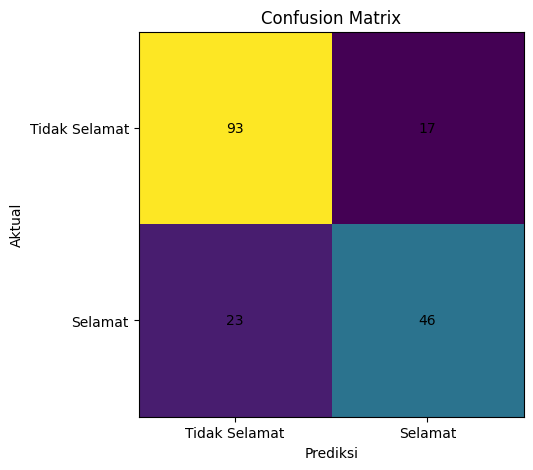

In [ ]:
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")

plt.xticks([0, 1], ["Tidak Selamat", "Selamat"])
plt.yticks([0, 1], ["Tidak Selamat", "Selamat"])

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.show()